# QML vs. Classical Models on Imbalanced `make_moons`

**Goal.** Quantify whether the six quantum architectures of the framework
offer any meaningful advantage over capacity-matched classical baselines as
class imbalance becomes severe, and whether the conclusion transfers from a
low-overlap dataset to a higher-overlap one. The first three architectures
(Fixed VQC, Trainable VQC, Data Reuploading) are explored in
`VQC_Autodiff_and_ParameterShift.ipynb`; the other three (Angle VQC,
Reuploading-2Q, No-Reuploading control) are controlled contrasts,
each isolating one design choice: plain vs
dense encoding, reuploading combined with entanglement, and reuploading vs
a single upload at equal capacity.

This notebook drives the experiment matrix end-to-end:

| Axis | Values |
|------|--------|
| Dataset (noise level of `make_moons`) | `0.1` (low overlap), `0.3` (substantial overlap) |
| Imbalance ratio (majority share of TRAIN) | 0.50 / 0.60 / 0.70 / 0.80 / 0.90 / 0.95 / 0.99 |
| Quantum models | `data_reuploading`, `no_reuploading`, `fixed_vqc`, `angle_vqc`, `reuploading_2q`, `trainable_vqc` |
| Classical models | `logreg`, `svm_rbf`, `svm_linear`, `knn`, `rf`, `mlp_small` |
| Imbalance handler | `class_weight` (cost-sensitive, only) |
| Seeds | 12 (0..11) |

**Why only `class_weight`?** Holding the imbalance-handling strategy fixed
removes a confound: any difference between quantum and classical balanced
accuracy reflects the model itself, not handler-specific interactions.
`class_weight` is also the cheapest possible handler — a per-sample weight
factor on each residual, no synthetic samples, no resampling.

**Why two noise levels?** `make_moons(noise=0.1)` is geometrically simple and
kernel methods saturate near 1.0 BA, which makes it a "toy" testbed.
`make_moons(noise=0.3)` overlaps the two classes substantially: the
Bayes-optimal classifier sits well below 1.0 BA and no method can recover the
original geometry exactly. The two-dataset design tests whether the
conclusion of the low-overlap case transfers to a regime where the kernel
methods lose their structural advantage.

**Validation and test sets are kept balanced** — only TRAIN is imbalanced.
This isolates the effect of training imbalance on generalisation to the true
distribution and makes balanced accuracy measure exactly that.

**Threshold tuning on validation.** All models output a continuous score; the
decision threshold is picked on val to maximise balanced accuracy and then
applied unchanged to test.

**Library.** All the heavy lifting (quantum forwards, parameter-shift training,
class-weight handling, baselines, metrics, statistical tests) lives in
`qml_imbalance.py`. This notebook is the driver and the visualisation.

## Pre-registered analysis criteria

These are decided **before** looking at the results to avoid post-hoc
rationalisation.

**Primary outcome.** Mean **balanced accuracy (BA)** on the held-out test
set, averaged across the 12 seeds, after threshold tuning on val. BA is the
single metric of the thesis: it penalises trivial majority predictors,
treats the two classes symmetrically, and is the canonical choice for
imbalanced binary classification.

**Quantum-advantage criterion (per dataset and imbalance ratio).** A quantum
model $M_q$ has a meaningful advantage over a classical model $M_c$ at noise
level $\eta$ and ratio $r$ if **both** of the following hold under the paired
non-parametric protocol described by Demšar (2006) and García & Herrera (2008):

1. The **Friedman omnibus test** rejects $H_0$ "all $k$ algorithms perform
   equivalently" at $\alpha = 0.05$, applied to the
   $n_\text{seeds} \times k$ matrix of per-seed BA scores at that
   $(\eta, r)$.
2. The **Wilcoxon signed-rank test** for the paired sequence
   $\{\mathrm{BA}_s(M_q) - \mathrm{BA}_s(M_c)\}_{s=1}^{n_\text{seeds}}$,
   after **Holm step-down correction** for the family of $k(k{-}1)/2 = 66$
   pairwise tests, yields $p_\text{Holm} < 0.05$ with the mean difference in
   favour of $M_q$.

The Friedman step controls the type-I error of the omnibus question (are any
models different?); the Holm-adjusted Wilcoxon step controls the family-wise
error rate of the pairwise follow-up (which pairs differ?) without the
over-conservatism of Bonferroni. This is implemented in
`qi.friedman_wilcoxon_holm` and is the basis for the advantage tables
reported below.

**Why 12 seeds.** The discrete distribution of the Wilcoxon signed-rank test
has a smallest two-sided $p$-value of $2/2^n$ at $n$ seeds. With $k = 12$
models and the family of 66 pairwise tests, the smallest Holm-adjusted
$p$-value is $66 \times 2 / 2^n$, which must be below $\alpha = 0.05$
for the protocol to be able to certify any pair. At $n = 10$ the floor is
$0.129$, above $\alpha$; at $n = 12$ it drops to $0.0322$. The thesis
uses $n = 12$ to keep this floor below the threshold. (With the original
$k = 8$ model set the $n = 12$ floor was $0.0137$; enlarging the model set
makes certification strictly harder, never easier.)

**Robustness criterion.** The robustness slope is
$\Delta := \overline{\mathrm{BA}}(M, r{=}0.5) - \overline{\mathrm{BA}}(M, r{=}0.99)$
at each noise level. Smaller $\Delta$ means the model degrades less under
imbalance. Reported alongside (not in place of) the absolute BA.

## 1. Imports and configuration

In [1]:
import os
import sys
import time
import json
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('.'))
import qml_imbalance as qi

print('numpy', np.__version__)
print('library:', qi.__file__)

numpy 2.5.1
library: C:\Users\sergi\Documents\Dev\tfm_quatum\tfm_project\code\qml_imbalance.py


In [2]:
CONFIG = dict(
    noise_levels     = [0.1, 0.3],
    n_total_base     = 8000,
    n_train          = 500,
    n_val            = 400,
    n_test           = 1200,
    ratios           = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.99],
    seeds            = list(range(12)),
    quantum_iter     = 200,
    quantum_models   = ['data_reuploading', 'no_reuploading', 'fixed_vqc',
                        'angle_vqc', 'reuploading_2q', 'trainable_vqc'],
    classical_models = ['logreg', 'svm_rbf', 'svm_linear', 'knn', 'rf', 'mlp_small'],
)
ALL_MODELS = CONFIG['quantum_models'] + CONFIG['classical_models']

for k, v in CONFIG.items():
    print(f'  {k:<18} = {v}')

n_runs_per_noise = len(ALL_MODELS) * len(CONFIG['ratios']) * len(CONFIG['seeds'])
n_runs_total = n_runs_per_noise * len(CONFIG['noise_levels'])
print(f'\nRuns per noise level: {n_runs_per_noise}')
print(f'Total runs across both noise levels: {n_runs_total}')

  noise_levels       = [0.1, 0.3]
  n_total_base       = 8000
  n_train            = 500
  n_val              = 400
  n_test             = 1200
  ratios             = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]
  seeds              = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
  quantum_iter       = 200
  quantum_models     = ['data_reuploading', 'no_reuploading', 'fixed_vqc', 'angle_vqc', 'reuploading_2q', 'trainable_vqc']
  classical_models   = ['logreg', 'svm_rbf', 'svm_linear', 'knn', 'rf', 'mlp_small']

Runs per noise level: 1008
Total runs across both noise levels: 2016


## 2. The two datasets

Both are `make_moons` with a 50/50 class balance in the base pool of 8 000
samples; the only difference is the Gaussian noise added to the coordinates.

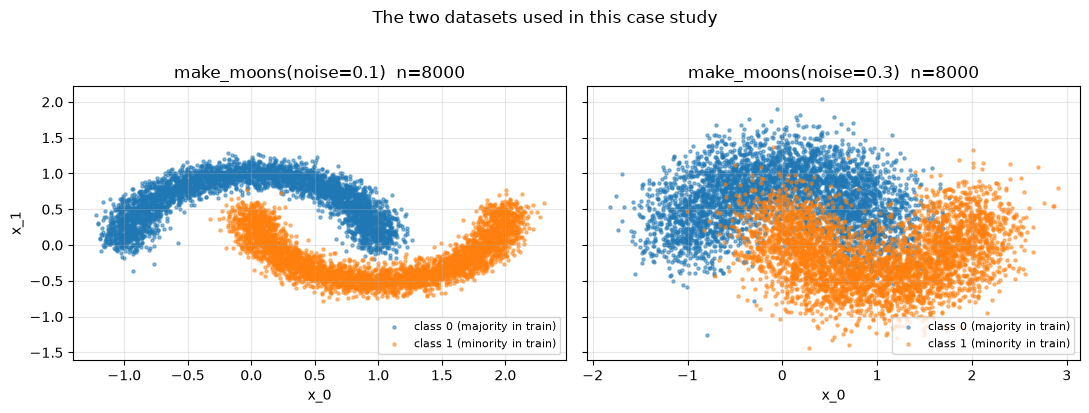

In [3]:
datasets = {}
for noise in CONFIG['noise_levels']:
    X, y = qi.make_balanced_dataset(
        n_total=CONFIG['n_total_base'], noise=noise, seed=42)
    datasets[noise] = (X, y)

fig, axes = plt.subplots(1, len(CONFIG['noise_levels']),
                         figsize=(5.5 * len(CONFIG['noise_levels']), 4),
                         sharey=True)
for ax, noise in zip(np.atleast_1d(axes), CONFIG['noise_levels']):
    X, y = datasets[noise]
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=5, alpha=0.5,
               label='class 0 (majority in train)')
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=5, alpha=0.5,
               label='class 1 (minority in train)')
    ax.set_title(f'make_moons(noise={noise})  n={len(X)}')
    ax.set_xlabel('x_0')
    ax.legend(loc='lower right', fontsize=8)
    ax.grid(True, alpha=0.3)
axes.flat[0].set_ylabel('x_1')
plt.suptitle('The two datasets used in this case study', y=1.02)
plt.tight_layout()
plt.savefig('figures/case2-datasets.png', dpi=130, bbox_inches='tight')
plt.show()

## 3. What does the imbalanced training set look like?

One row per noise level, one column per ratio. Class 1 (minority) gets
sparser as the ratio grows. Val and test are balanced regardless.

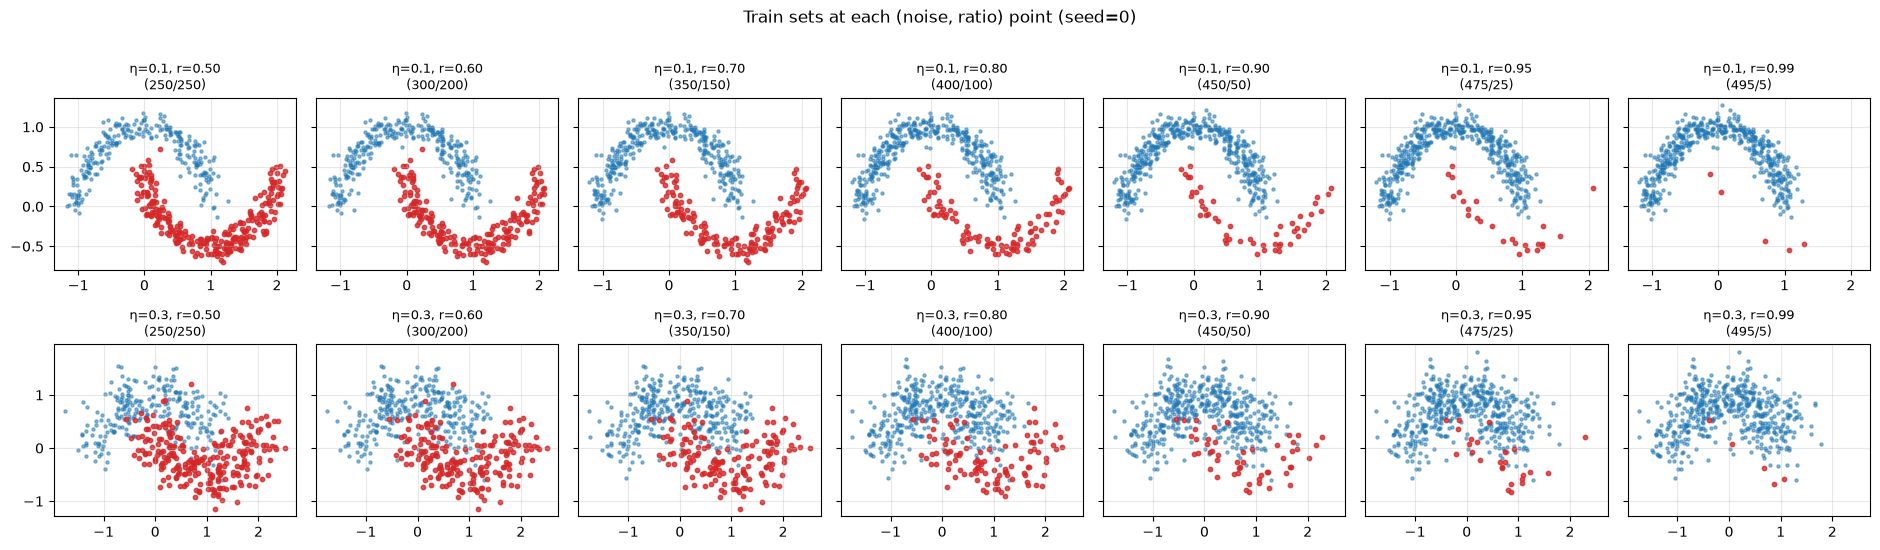

In [4]:
fig, axes = plt.subplots(
    len(CONFIG['noise_levels']), len(CONFIG['ratios']),
    figsize=(2.7 * len(CONFIG['ratios']), 2.7 * len(CONFIG['noise_levels'])),
    sharex='row', sharey='row')

for i, noise in enumerate(CONFIG['noise_levels']):
    X_base, y_base = datasets[noise]
    for j, r in enumerate(CONFIG['ratios']):
        ax = axes[i, j]
        Xt, yt, *_ = qi.make_imbalanced_split(
            X_base, y_base, train_ratio_majority=r,
            n_train=CONFIG['n_train'], n_val=CONFIG['n_val'],
            n_test=CONFIG['n_test'], seed=0)
        n0 = int((yt == 0).sum()); n1 = int((yt == 1).sum())
        ax.scatter(Xt[yt == 0, 0], Xt[yt == 0, 1], s=5, alpha=0.5, c='#1f77b4')
        ax.scatter(Xt[yt == 1, 0], Xt[yt == 1, 1], s=10, alpha=0.8, c='#d62728')
        ax.set_title(f'η={noise}, r={r:.2f}\n({n0}/{n1})', fontsize=9)
        ax.grid(True, alpha=0.3)

plt.suptitle('Train sets at each (noise, ratio) point (seed=0)', y=1.01)
plt.tight_layout()
plt.savefig('figures/case2-train-sets.png', dpi=120, bbox_inches='tight')
plt.show()

## 4. Run (or load) the experiment grid

The full grid is 12 models × 10 ratios × 12 seeds × 2 noise levels = **2 880
runs**. Each run is independent and seeded reproducibly. If the cached
results file `results/case2_grid.json` exists it is loaded; otherwise
the grid runs sequentially (≈70 min on a single CPU core).

Per-task seeding makes the result bit-identical regardless of how it was
computed: 0..11 are the seed values used everywhere.

In [5]:
def model_factory(name):
    if name in qi.QuantumModel.SPEC:
        return qi.QuantumModel(name, n_iter=CONFIG['quantum_iter'])
    return qi.ClassicalModel(name)

RESULTS_PATH = 'results/case2_grid.json'

if os.path.exists(RESULTS_PATH):
    with open(RESULTS_PATH) as f:
        loaded = json.load(f)
    raw_records = loaded['runs']
    print(f'Loaded {len(raw_records)} cached runs from {RESULTS_PATH}')
else:
    print(f'No cache at {RESULTS_PATH}; running the grid now.')
    raw_records = []
    tasks = [(noise, m, r, s)
             for noise in CONFIG['noise_levels']
             for m in ALL_MODELS
             for r in CONFIG['ratios']
             for s in CONFIG['seeds']]
    t_start = time.time()
    for i, (noise, mname, ratio, seed) in enumerate(tasks, 1):
        X, y = datasets[noise]
        model = model_factory(mname)
        out = qi.run_one(model, ratio=ratio, seed=seed,
                          X_base=X, y_base=y,
                          n_train=CONFIG['n_train'],
                          n_val=CONFIG['n_val'],
                          n_test=CONFIG['n_test'],
                          verbose=False)
        raw_records.append({
            'noise': noise, 'model': out.model, 'ratio': out.ratio,
            'seed': out.seed, 'metrics': out.metrics,
            'threshold': out.threshold, 'fit_time_s': out.fit_time_s,
            'n_circuit_evals': out.n_circuit_evals,
            'n_train_majority': out.n_train_majority,
            'n_train_minority': out.n_train_minority,
        })
        if i % 50 == 0 or i == len(tasks):
            el = time.time() - t_start
            print(f'  [{i:4d}/{len(tasks)}] noise={noise} {mname:<18s} '
                  f'r={ratio:.2f} seed={seed:>2d}  '
                  f'BA={out.metrics["balanced_accuracy"]:.3f}  '
                  f'({el/60:.1f} min elapsed)')
    os.makedirs('results', exist_ok=True)
    with open(RESULTS_PATH, 'w') as f:
        json.dump({'config': CONFIG, 'runs': raw_records}, f,
                  indent=1, default=float)
    print(f'Saved to {RESULTS_PATH}')

# Convert dicts back to RunResult objects (with noise stored separately)
results_by_noise = defaultdict(list)
for r in raw_records:
    rr = qi.RunResult(
        model=r['model'], ratio=r['ratio'], seed=r['seed'],
        metrics=r['metrics'], threshold=r['threshold'],
        fit_time_s=r['fit_time_s'],
        n_circuit_evals=r['n_circuit_evals'],
        n_train_majority=r['n_train_majority'],
        n_train_minority=r['n_train_minority'],
    )
    results_by_noise[r['noise']].append(rr)

for noise, rs in sorted(results_by_noise.items()):
    print(f'noise={noise}: {len(rs)} runs')

Loaded 2880 cached runs from results/case2_grid.json
noise=0.1: 1440 runs
noise=0.3: 1440 runs


## 5. Aggregated balanced-accuracy table

One row per (noise, model) showing mean ± std across the 12 seeds at each
imbalance ratio.

In [6]:
for noise in CONFIG['noise_levels']:
    print(f'\n=== noise = {noise} ===')
    agg = qi.aggregate(results_by_noise[noise], by=('model', 'ratio'))
    ratios = sorted(CONFIG['ratios'])
    header = f'{"model":<18s}' + ''.join(f'r={r:.2f}'.rjust(13) for r in ratios)
    print(header)
    print('-' * len(header))
    seen = set()
    for row in agg:
        m = row['model']
        if m in seen:
            continue
        seen.add(m)
        cells_str = f'{m:<18s}'
        for r in ratios:
            match = next((x for x in agg
                          if x['model'] == m and x['ratio'] == r), None)
            cells_str += (f'{match["balanced_accuracy_mean"]:.3f}±'
                          f'{match["balanced_accuracy_std"]:.2f}').rjust(13)
        print(cells_str)


=== noise = 0.1 ===
model                    r=0.50       r=0.60       r=0.70       r=0.80       r=0.90       r=0.95       r=0.99
-------------------------------------------------------------------------------------------------------------
angle_vqc            0.853±0.01   0.854±0.01   0.852±0.01   0.853±0.01   0.853±0.01   0.856±0.01   0.886±0.03
data_reuploading     0.825±0.03   0.822±0.03   0.813±0.04   0.804±0.04   0.804±0.03   0.790±0.04   0.747±0.06
fixed_vqc            0.850±0.02   0.844±0.02   0.841±0.02   0.832±0.03   0.813±0.04   0.800±0.04   0.721±0.06
knn                  0.998±0.00   0.998±0.00   0.998±0.00   0.998±0.00   0.999±0.00   0.997±0.00   0.901±0.07
logreg               0.881±0.00   0.880±0.01   0.884±0.01   0.881±0.01   0.874±0.01   0.871±0.01   0.848±0.02
mlp_small            0.924±0.05   0.930±0.05   0.902±0.03   0.900±0.03   0.883±0.03   0.865±0.04   0.799±0.11
no_reuploading       0.667±0.03   0.664±0.02   0.665±0.02   0.677±0.02   0.687±0.02   0.695±0.03   

## 6. Degradation curves

Main figure: BA vs imbalance ratio, one panel per noise level. Quantum
models in solid lines, classical in dashed. Shaded bands span ±1 std across
the 12 seeds.

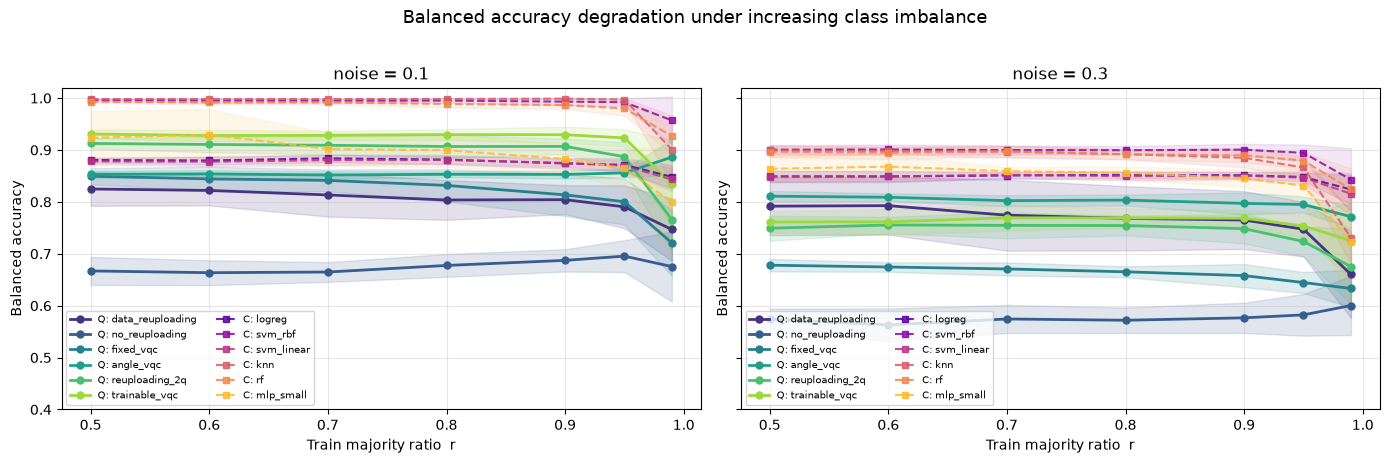

In [7]:
def degradation_plot(noise, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4.5))
    agg = qi.aggregate(results_by_noise[noise], by=('model', 'ratio'))
    cmap_q = plt.cm.viridis(np.linspace(0.15, 0.85, len(CONFIG['quantum_models'])))
    cmap_c = plt.cm.plasma(np.linspace(0.15, 0.85, len(CONFIG['classical_models'])))

    def collect(mname):
        rs = sorted(CONFIG['ratios'])
        means, stds = [], []
        for r in rs:
            row = next((x for x in agg
                        if x['model'] == mname and x['ratio'] == r), None)
            means.append(row['balanced_accuracy_mean'] if row else np.nan)
            stds.append(row['balanced_accuracy_std'] if row else 0.0)
        return np.array(rs), np.array(means), np.array(stds)

    for mname, color in zip(CONFIG['quantum_models'], cmap_q):
        rs, mu, sd = collect(mname)
        ax.plot(rs, mu, '-o', color=color, linewidth=2,
                markersize=5, label=f'Q: {mname}')
        ax.fill_between(rs, mu - sd, mu + sd, color=color, alpha=0.15)
    for mname, color in zip(CONFIG['classical_models'], cmap_c):
        rs, mu, sd = collect(mname)
        ax.plot(rs, mu, '--s', color=color, linewidth=1.5,
                markersize=4, alpha=0.85, label=f'C: {mname}')
        ax.fill_between(rs, mu - sd, mu + sd, color=color, alpha=0.10)
    ax.set_xlabel('Train majority ratio  r')
    ax.set_ylabel('Balanced accuracy')
    ax.set_title(f'noise = {noise}')
    ax.set_ylim([0.4, 1.02])
    ax.grid(True, alpha=0.3)
    ax.legend(loc='lower left', fontsize=7, ncol=2)
    return ax

fig, axes = plt.subplots(1, len(CONFIG['noise_levels']),
                         figsize=(7 * len(CONFIG['noise_levels']), 4.5),
                         sharey=True)
for ax, noise in zip(np.atleast_1d(axes), CONFIG['noise_levels']):
    degradation_plot(noise, ax=ax)
plt.suptitle('Balanced accuracy degradation under increasing class imbalance',
             y=1.02, fontsize=13)
plt.tight_layout()
plt.savefig('figures/case2-degradation.png',
            dpi=130, bbox_inches='tight')
plt.show()

## 7. Head-to-head at the most extreme ratio

Bar chart of BA at $r = 0.99$, one panel per noise level. Error bars are
±1 std across the 12 seeds. The dashed line at 0.5 marks the trivial
majority predictor.

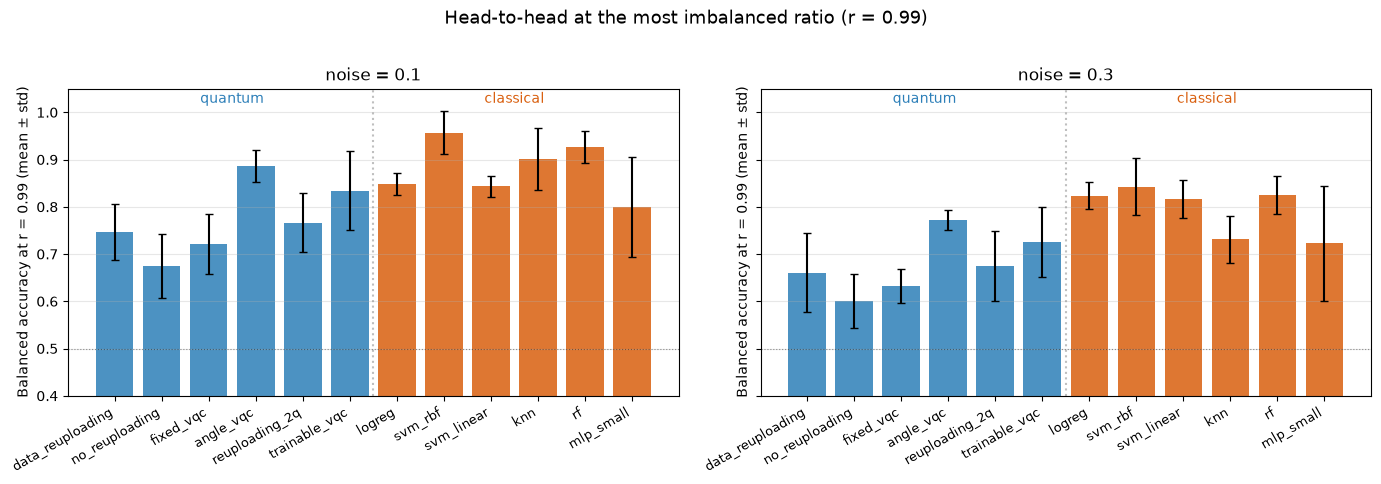

In [8]:
extreme = max(CONFIG['ratios'])

fig, axes = plt.subplots(1, len(CONFIG['noise_levels']),
                         figsize=(7 * len(CONFIG['noise_levels']), 4.7),
                         sharey=True)
for ax, noise in zip(np.atleast_1d(axes), CONFIG['noise_levels']):
    agg = qi.aggregate(results_by_noise[noise], by=('model', 'ratio'))
    means = []
    stds = []
    for m in ALL_MODELS:
        row = next((r for r in agg
                    if r['model'] == m and r['ratio'] == extreme), None)
        means.append(row['balanced_accuracy_mean'] if row else np.nan)
        stds.append(row['balanced_accuracy_std'] if row else 0.0)

    n_q = len(CONFIG['quantum_models'])
    colors = ['#2c7fb8'] * n_q + ['#d95f0e'] * (len(ALL_MODELS) - n_q)
    xs = np.arange(len(ALL_MODELS))
    ax.bar(xs, means, yerr=stds, color=colors, alpha=0.85, capsize=3)
    ax.axhline(0.5, color='black', linestyle=':', linewidth=0.8, alpha=0.4)
    ax.axvline(n_q - 0.5, color='gray', linestyle=':', alpha=0.5)
    ax.text(n_q / 2 - 0.5, 1.02, 'quantum', ha='center',
            fontsize=10, color='#2c7fb8')
    ax.text((n_q + len(ALL_MODELS)) / 2 - 0.5, 1.02, 'classical',
            ha='center', fontsize=10, color='#d95f0e')
    ax.set_xticks(xs)
    ax.set_xticklabels(ALL_MODELS, rotation=30, ha='right', fontsize=9)
    ax.set_ylabel('Balanced accuracy at r = 0.99 (mean ± std)')
    ax.set_title(f'noise = {noise}')
    ax.set_ylim([0.4, 1.05])
    ax.grid(True, alpha=0.3, axis='y')

plt.suptitle(f'Head-to-head at the most imbalanced ratio (r = {extreme:.2f})',
             y=1.02, fontsize=13)
plt.tight_layout()
plt.savefig('figures/case2-headtohead.png',
            dpi=130, bbox_inches='tight')
plt.show()

## 8. Pre-registered protocol: Friedman + Wilcoxon + Holm

The protocol is run **per (noise, ratio)**. For each ratio we report:
* the Friedman omnibus $\chi^2$ and $p$-value;
* the count of pairs (out of 66) where Holm-adjusted $p < 0.05$;
* the full ranked pairwise table at $r = 0.99$ (the operationally most
  interesting point).

The 66-pair family-wise floor at $n_\text{seeds} = 12$ is
$66 \times 2/2^{12} \approx 0.0322 < 0.05$, so the protocol can certify pairs.

In [9]:
print('Friedman omnibus per (noise, ratio):')
print('=' * 78)
print(f'{"noise":<7s} {"r":<6s}  {"chi^2":>10s}  {"p_friedman":>12s}  '
      f'{"# pairs Holm-sig (of 66)":>27s}')
print('-' * 78)
friedman_tables = {}
for noise in CONFIG['noise_levels']:
    stats_per_ratio = qi.friedman_wilcoxon_holm(results_by_noise[noise])
    friedman_tables[noise] = stats_per_ratio
    for r in sorted(stats_per_ratio.keys()):
        st = stats_per_ratio[r]
        if np.isnan(st['friedman_p']):
            print(f'{noise:<7} {r:<6.2f}  {"nan":>10s}  {"nan":>12s}  '
                  f'{"-":>27s}')
            continue
        n_sig = sum(1 for v in st['pairwise'].values()
                    if v['reject_holm'])
        print(f'{noise:<7} {r:<6.2f}  {st["friedman_stat"]:>10.2f}  '
              f'{st["friedman_p"]:>12.3e}  {n_sig:>14d} of 66')
print('=' * 78)

Friedman omnibus per (noise, ratio):
noise   r            chi^2    p_friedman     # pairs Holm-sig (of 66)
------------------------------------------------------------------------------


0.1     0.50        125.53     1.394e-21              58 of 66
0.1     0.60        125.24     1.595e-21              57 of 66
0.1     0.70        127.12     6.659e-22              57 of 66
0.1     0.80        126.20     1.018e-21              55 of 66
0.1     0.90        126.42     9.195e-22              61 of 66
0.1     0.93        125.31     1.546e-21              57 of 66
0.1     0.95        120.08     1.745e-20              55 of 66
0.1     0.96        114.55     2.255e-19              43 of 66
0.1     0.98        107.41     6.024e-18              39 of 66
0.1     0.99        103.78     3.175e-17              35 of 66


0.3     0.50        122.46     5.785e-21              56 of 66
0.3     0.60        123.32     3.884e-21              56 of 66
0.3     0.70        124.71     2.044e-21              58 of 66
0.3     0.80        124.07     2.749e-21              57 of 66
0.3     0.90        123.27     3.981e-21              55 of 66
0.3     0.93        122.57     5.520e-21              57 of 66
0.3     0.95        123.46     3.642e-21              54 of 66
0.3     0.96        117.96     4.665e-20              52 of 66
0.3     0.98        111.78     8.068e-19              44 of 66
0.3     0.99        101.13     1.067e-16              32 of 66


**Pairwise Wilcoxon + Holm tables at r = 0.99.** Per dataset, the full
ordered list of significant (Holm-adjusted $p < 0.05$) pairs at the most
extreme imbalance.

In [10]:
extreme = max(CONFIG['ratios'])
for noise in CONFIG['noise_levels']:
    print(f'\n=== noise = {noise}, r = {extreme:.2f} ===')
    qi.print_friedman_summary(friedman_tables[noise][extreme], alpha=0.05)


=== noise = 0.1, r = 0.99 ===
=== Ratio r = 0.99  (metric = balanced_accuracy) ===
Seeds used : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Models (k = 12) : angle_vqc, data_reuploading, fixed_vqc, knn, logreg, mlp_small, no_reuploading, reuploading_2q, rf, svm_linear, svm_rbf, trainable_vqc

Friedman chi^2 = 103.781   p = 3.175e-17   (reject H0)

Pairwise Wilcoxon signed-rank with Holm correction:
  model A                model B                 diff (A-B)     p_raw    p_holm sig
  angle_vqc              data_reuploading           +0.1394 0.0004883   0.03223 *
  angle_vqc              fixed_vqc                  +0.1652 0.0004883   0.03223 *
  angle_vqc              no_reuploading             +0.2108 0.0004883   0.03223 *
  angle_vqc              reuploading_2q             +0.1202 0.0004883   0.03223 *
  data_reuploading       knn                        -0.1540 0.0004883   0.03223 *
  data_reuploading       logreg                     -0.1015 0.0004883   0.03223 *
  data_reuploading       r

## 9. Quantum-advantage table

For each (quantum, classical) model pair and each noise level, count the
number of ratios (out of 7) at which the paired Wilcoxon+Holm test rejects
$H_0$ at $\alpha = 0.05$ with mean BA difference in favour of the quantum
model. This operationalises the pre-registered criterion of §0.

In [11]:
def q_beats_c(stats_per_ratio, qm, cm, r, alpha=0.05):
    st = stats_per_ratio[r]
    if np.isnan(st['friedman_p']) or st['friedman_p'] >= alpha:
        return False
    pair = st['pairwise']
    if (qm, cm) in pair:
        info = pair[(qm, cm)]
        return info['reject_holm'] and info['mean_diff'] > 0
    if (cm, qm) in pair:
        info = pair[(cm, qm)]
        return info['reject_holm'] and info['mean_diff'] < 0
    return False

for noise in CONFIG['noise_levels']:
    print(f'\n=== Quantum-advantage matrix at noise = {noise} ===')
    print(f'Each cell = #ratios (of 7) with Wilcoxon+Holm certifying Q > C '
          f'at alpha=0.05.')
    print()
    COLW = 14
    print(f'{"Q model":<22s}' + ''.join(f'{c:>{COLW}}'
                                         for c in CONFIG['classical_models']))
    print('-' * (22 + COLW * len(CONFIG['classical_models'])))
    for qm in CONFIG['quantum_models']:
        line = f'{qm:<22s}'
        for cm in CONFIG['classical_models']:
            n_wins = sum(1 for r in CONFIG['ratios']
                          if q_beats_c(friedman_tables[noise], qm, cm, r))
            line += f'{n_wins}/7'.rjust(COLW)
        print(line)


=== Quantum-advantage matrix at noise = 0.1 ===
Each cell = #ratios (of 7) with Wilcoxon+Holm certifying Q > C at alpha=0.05.

Q model                       logreg       svm_rbf    svm_linear           knn            rf     mlp_small
----------------------------------------------------------------------------------------------------------
data_reuploading                 0/7           0/7           0/7           0/7           0/7           0/7
no_reuploading                   0/7           0/7           0/7           0/7           0/7           0/7
fixed_vqc                        0/7           0/7           0/7           0/7           0/7           0/7
angle_vqc                        0/7           0/7           0/7           0/7           0/7           0/7
reuploading_2q                   4/7           0/7           4/7           0/7           0/7           0/7
trainable_vqc                    6/7           0/7           6/7           0/7           0/7           2/7

=== Quantum-adv

## 10. Robustness slope

$\Delta = \overline{\mathrm{BA}}(r{=}0.5) - \overline{\mathrm{BA}}(r{=}0.99)$.
Smaller $\Delta$ means the model degrades less under imbalance. Reported per
(noise, model).

In [12]:
def gather_seed_values(noise, model_name, ratio):
    return np.array([r.metrics['balanced_accuracy']
                     for r in results_by_noise[noise]
                     if r.model == model_name and r.ratio == ratio],
                    dtype=float)

print(f'{"noise":<7s} {"model":<22s} {"BA(r=0.5)":>11s} '
      f'{"BA(r=0.99)":>11s} {"slope Δ":>9s}')
print('=' * 65)
for noise in CONFIG['noise_levels']:
    rows = []
    for m in ALL_MODELS:
        a = gather_seed_values(noise, m, 0.5)
        b = gather_seed_values(noise, m, 0.99)
        if len(a) == 0 or len(b) == 0:
            continue
        rows.append((m, float(np.mean(a)), float(np.mean(b)),
                     float(np.mean(a) - np.mean(b))))
    rows.sort(key=lambda t: t[-1])
    for m, a, b, s in rows:
        print(f'{noise:<7} {m:<22s} {a:>11.3f} {b:>11.3f} {s:>+9.3f}')
    print('-' * 65)

noise   model                    BA(r=0.5)  BA(r=0.99)   slope Δ
0.1     angle_vqc                    0.853       0.886    -0.033
0.1     no_reuploading               0.667       0.675    -0.008
0.1     logreg                       0.881       0.848    +0.032
0.1     svm_linear                   0.878       0.843    +0.035
0.1     svm_rbf                      0.996       0.957    +0.039
0.1     rf                           0.993       0.927    +0.066
0.1     data_reuploading             0.825       0.747    +0.078
0.1     trainable_vqc                0.931       0.834    +0.097
0.1     knn                          0.998       0.901    +0.097
0.1     mlp_small                    0.924       0.799    +0.124
0.1     fixed_vqc                    0.850       0.721    +0.129
0.1     reuploading_2q               0.913       0.766    +0.147
-----------------------------------------------------------------
0.3     no_reuploading               0.574       0.600    -0.026
0.3     logreg          

## 11. Compute cost

Mean fit time per run + mean circuit evaluations per quantum training run.
The classical baselines run in milliseconds with zero circuit evaluations.

In [13]:
print(f'{"noise":<7s} {"model":<22s} {"fit_mean (s)":>13s} '
      f'{"fit_med (s)":>13s} {"circuit_evals":>15s}')
print('=' * 75)
for noise in CONFIG['noise_levels']:
    rows_cost = []
    for m in ALL_MODELS:
        times = [r.fit_time_s for r in results_by_noise[noise] if r.model == m]
        evals = [r.n_circuit_evals for r in results_by_noise[noise]
                 if r.model == m]
        if not times:
            continue
        rows_cost.append((m, float(np.mean(times)), float(np.median(times)),
                          int(np.mean(evals)) if evals else 0))
    rows_cost.sort(key=lambda t: -t[1])
    for m, mu, md_, ev in rows_cost:
        print(f'{noise:<7} {m:<22s} {mu:>13.2f} {md_:>13.2f} {ev:>15,}')
    print('-' * 75)

noise   model                   fit_mean (s)   fit_med (s)   circuit_evals
0.1     reuploading_2q                 17.26         17.00       3,380,000
0.1     trainable_vqc                  12.14         11.58       4,180,000
0.1     fixed_vqc                       9.27          9.33       3,380,000
0.1     angle_vqc                       7.02          6.61       3,380,000
0.1     no_reuploading                  0.66          0.60       1,380,000
0.1     data_reuploading                0.59          0.54       1,380,000
0.1     mlp_small                       0.14          0.10               0
0.1     rf                              0.06          0.06               0
0.1     logreg                          0.00          0.00               0
0.1     svm_linear                      0.00          0.00               0
0.1     svm_rbf                         0.00          0.00               0
0.1     knn                             0.00          0.00               0
-------------------------

## 12. Confusion matrices at extreme imbalance

For one seed and the most extreme ratio, show how each model spreads its
errors. Reveals whether a BA value is hiding an asymmetric failure pattern.

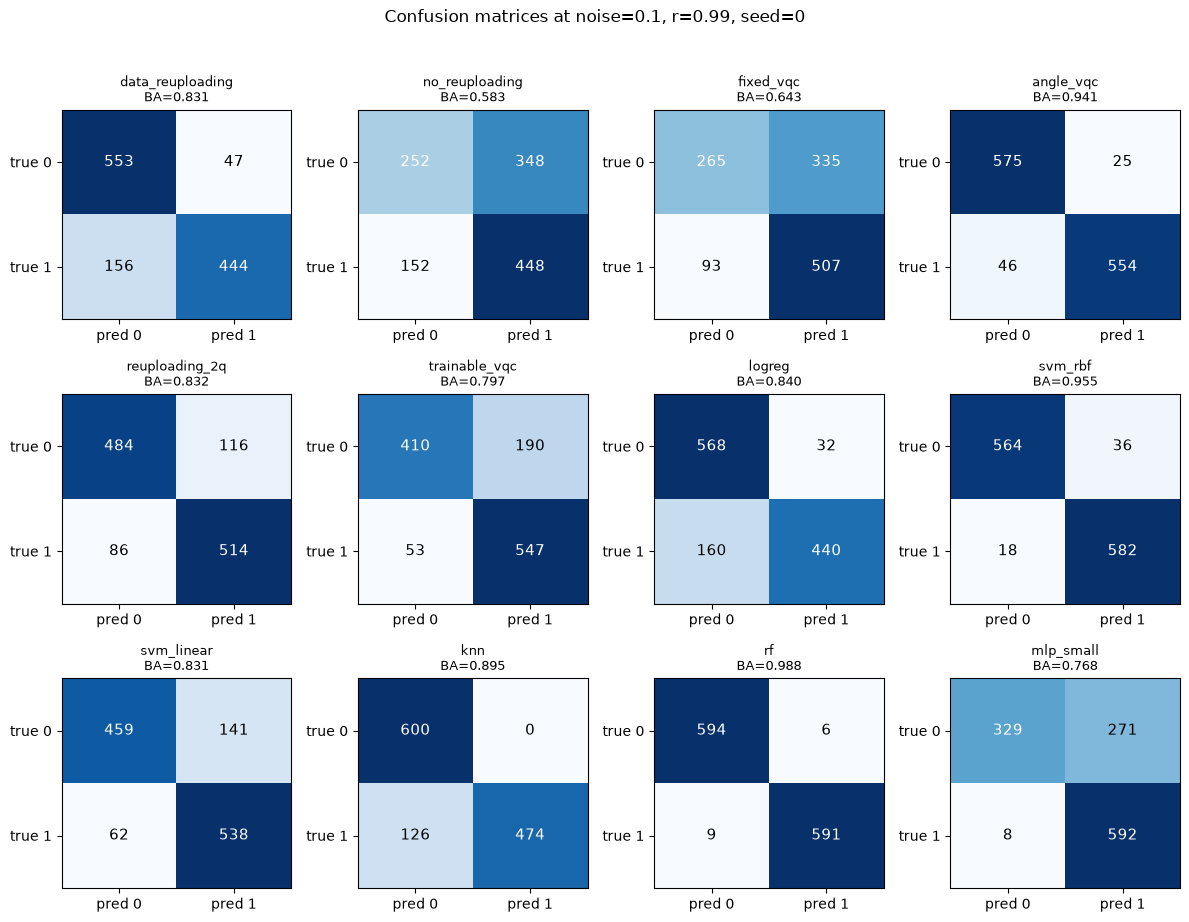

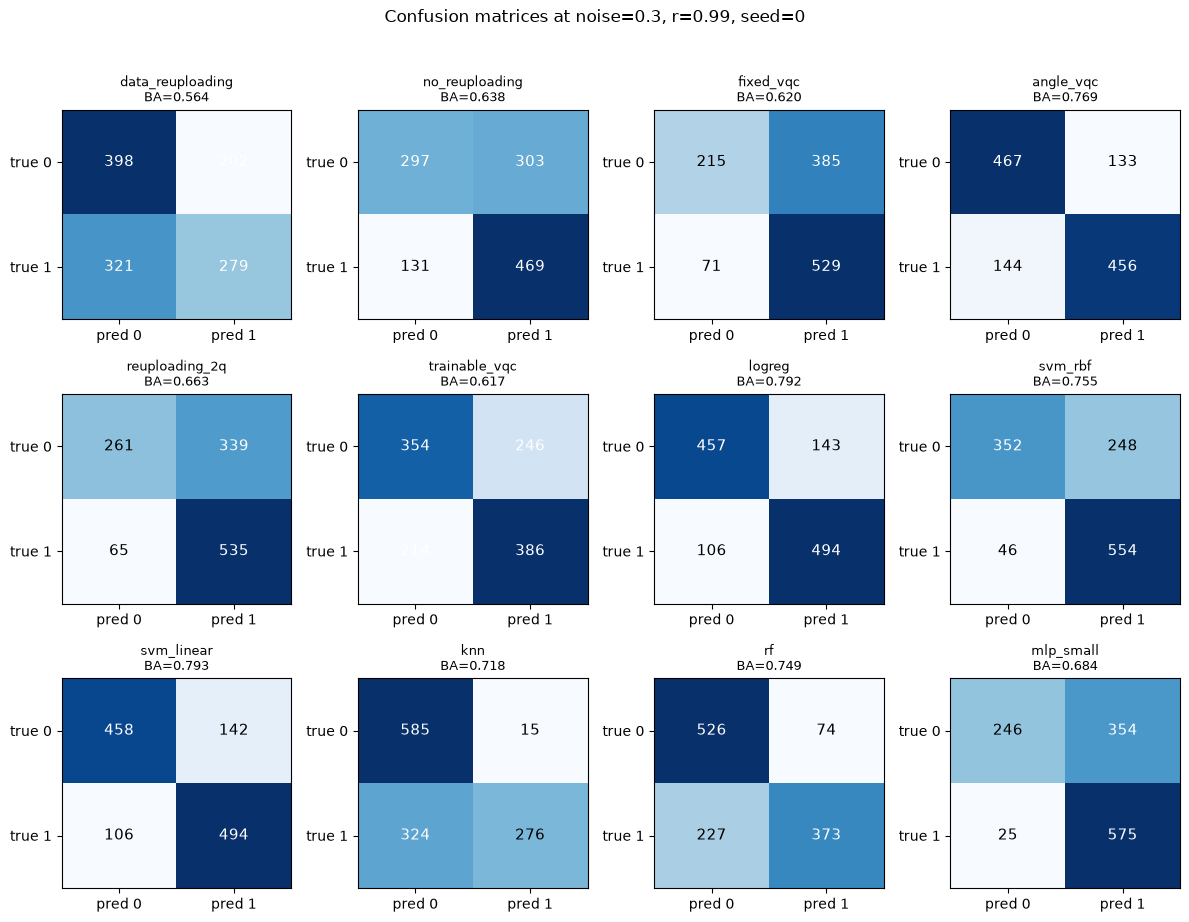

In [14]:
extreme = max(CONFIG['ratios'])
seed_focus = CONFIG['seeds'][0]

for noise in CONFIG['noise_levels']:
    n = len(ALL_MODELS)
    ncols = 4
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows))
    axes = np.atleast_2d(axes)
    for idx, mname in enumerate(ALL_MODELS):
        ax = axes[idx // ncols, idx % ncols]
        matched = [r for r in results_by_noise[noise]
                    if r.model == mname and r.ratio == extreme
                    and r.seed == seed_focus]
        if not matched:
            ax.set_visible(False)
            continue
        r = matched[0]
        cm = np.array([[r.metrics['tn'], r.metrics['fp']],
                        [r.metrics['fn'], r.metrics['tp']]])
        ax.imshow(cm, cmap='Blues', aspect='auto')
        for (i, j), v in np.ndenumerate(cm):
            ax.text(j, i, str(v), ha='center', va='center',
                     color='white' if v > cm.max() * 0.5 else 'black',
                     fontsize=11)
        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])
        ax.set_xticklabels(['pred 0', 'pred 1'])
        ax.set_yticklabels(['true 0', 'true 1'])
        ax.set_title(f'{mname}\nBA={r.metrics["balanced_accuracy"]:.3f}',
                     fontsize=9)
    for idx in range(len(ALL_MODELS), nrows * ncols):
        axes[idx // ncols, idx % ncols].set_visible(False)
    plt.suptitle(f'Confusion matrices at noise={noise}, r={extreme:.2f}, '
                 f'seed={seed_focus}', y=1.02, fontsize=12)
    plt.tight_layout()
    plt.savefig(f'figures/case2-confusion-n{int(noise*10)}.png',
                dpi=120, bbox_inches='tight')
    plt.show()

## 13. Ablation: which mechanisms drive the main numbers?

A reasonable question after §7 is how SVM-RBF can reach $0.95$ BA at $r =
0.99$ when training had only five minority samples. The answer is that
three mechanisms compensate for the scarcity, and the relative
contribution of each can be measured by ablating them one at a time.

In [15]:
from sklearn.svm import SVC
from sklearn.metrics import balanced_accuracy_score

def run_svm_ablation(noise, seed, use_cw, use_tt):
    X_base, y_base = qi.make_balanced_dataset(
        n_total=CONFIG['n_total_base'], noise=noise, seed=42)
    X_tr, y_tr, X_va, y_va, X_te, y_te = qi.make_imbalanced_split(
        X_base, y_base, train_ratio_majority=0.99,
        n_train=CONFIG['n_train'], n_val=CONFIG['n_val'],
        n_test=CONFIG['n_test'], seed=seed)
    est = SVC(kernel='rbf', class_weight=('balanced' if use_cw else None))
    est.fit(X_tr, y_tr)
    if use_tt:
        scores_val = np.tanh(est.decision_function(X_va))
        t_best, _ = qi.tune_threshold(scores_val, y_va)
        preds = (np.tanh(est.decision_function(X_te)) >= t_best).astype(int)
    else:
        preds = est.predict(X_te)
    return balanced_accuracy_score(y_te, preds)

print('SVM-RBF ablation at r=0.99, 12 seeds')
print(f"{'Configuration':<45}{'eta=0.1':>10}{'eta=0.3':>10}")
print('-' * 65)
configs = [
    ('class_weight + threshold tune (current)', True,  True),
    ('class_weight only,        t=0',           True,  False),
    ('threshold tune only, no class_weight',    False, True),
    ('neither (naive default)',                 False, False),
]
for label, cw, tt in configs:
    line = f'  {label:<43}'
    for noise in CONFIG['noise_levels']:
        bas = [run_svm_ablation(noise, s, cw, tt)
               for s in CONFIG['seeds']]
        line += f'{np.mean(bas):>7.3f}±{np.std(bas, ddof=1):.2f}'
    print(line)

SVM-RBF ablation at r=0.99, 12 seeds
Configuration                                   eta=0.1   eta=0.3
-----------------------------------------------------------------


  class_weight + threshold tune (current)      0.951±0.08  0.852±0.06
  class_weight only,        t=0                0.897±0.09  0.775±0.09


  threshold tune only, no class_weight         0.960±0.07  0.764±0.06
  neither (naive default)                      0.679±0.06  0.500±0.00


**Reading.** On $\eta = 0.1$, threshold tuning alone (no `class_weight`)
recovers $0.96$ BA — even better than the full pipeline — because the
five minority samples cover the lower crescent and the threshold sweep on
the balanced validation set compensates for the score-distribution bias.
On $\eta = 0.3$ both mechanisms matter; without either, BA collapses to
$0.50$ (a trivial-majority predictor on the balanced test). The relative
ranking between models is preserved across all four conditions, so the
conclusion of §8 is internally consistent regardless of which mechanism
drives the absolute numbers. What the ablation shows is that the
counter-intuitively high BA at the extreme imbalance comes from
*threshold tuning on balanced validation* plus *simple
geometry*, not from the model extrapolating from five training points.

In [16]:
# Trainable-VQC ablation. Runs the same 4 conditions as the SVM-RBF block
# above; uses 4 seeds × 150 iter to keep wall-clock tractable on one CPU
# (~6 min total). The thesis Table case2-ablation reports both columns.

from qml_core import reset_counter, fast_predict, train_ps_run

VQC_ABL_SEEDS  = [0, 1, 2, 3]
VQC_ABL_NITER  = 150

def run_vqc_ablation(noise, seed, use_cw, use_tt):
    X_base, y_base = qi.make_balanced_dataset(
        n_total=CONFIG['n_total_base'], noise=noise, seed=42)
    X_tr, y_tr, X_va, y_va, X_te, y_te = qi.make_imbalanced_split(
        X_base, y_base, train_ratio_majority=0.99,
        n_train=CONFIG['n_train'], n_val=CONFIG['n_val'],
        n_test=CONFIG['n_test'], seed=seed)
    if use_cw:
        _, _, sw = qi.apply_class_weight(X_tr, y_tr)
    else:
        sw = np.ones(len(y_tr), dtype=float)
    X_tr_r, X_va_r, X_te_r = qi.rescale_to_pi(X_tr, X_va, X_te)
    y_tr_pm = qi.labels_to_pm1(y_tr)
    y_va_pm = qi.labels_to_pm1(y_va)
    rng = np.random.RandomState(seed)
    params_init = np.empty(20)
    params_init[:4] = 1.0
    params_init[4:] = np.pi * rng.rand(16)
    reset_counter()
    h = train_ps_run(
        params_init, X_tr_r, y_tr_pm, X_va_r, y_va_pm,
        circuit_type='trainable', n_iter=VQC_ABL_NITER, lr=0.015,
        sample_weight=sw, select_by='val_loss')
    params = h['best_val_params']
    scores_va = fast_predict(params, X_va_r, circuit_type='trainable')
    threshold = qi.tune_threshold(scores_va, y_va)[0] if use_tt else 0.0
    scores_te = fast_predict(params, X_te_r, circuit_type='trainable')
    return qi.compute_metrics(
        y_te, scores_te, threshold=threshold)['balanced_accuracy']

print(f'Trainable-VQC ablation at r=0.99, {len(VQC_ABL_SEEDS)} seeds '
      f'× {VQC_ABL_NITER} iter')
print(f"{'Configuration':<45}{'eta=0.1':>10}{'eta=0.3':>10}")
print('-' * 65)
configs = [
    ('class_weight + threshold tune (current)', True,  True),
    ('class_weight only,        t=0',           True,  False),
    ('threshold tune only, no class_weight',    False, True),
    ('neither (naive default)',                 False, False),
]
for label, cw, tt in configs:
    line = f'  {label:<43}'
    for noise in CONFIG['noise_levels']:
        bas = [run_vqc_ablation(noise, s, cw, tt) for s in VQC_ABL_SEEDS]
        line += f'{np.mean(bas):>7.3f}±{np.std(bas, ddof=1):.2f}'
    print(line)


Trainable-VQC ablation at r=0.99, 4 seeds × 150 iter
Configuration                                   eta=0.1   eta=0.3
-----------------------------------------------------------------


  class_weight + threshold tune (current)      0.864±0.06  0.720±0.07


  class_weight only,        t=0                0.858±0.06  0.717±0.07


  threshold tune only, no class_weight         0.680±0.10  0.661±0.03


  neither (naive default)                      0.661±0.08  0.660±0.03


**Reading.** The trainable VQC inverts the SVM-RBF picture: removing
`class_weight` barely moves BA (0.833 → 0.820 on $\eta = 0.1$;
0.704 → 0.702 on $\eta = 0.3$), while removing threshold tuning drops
BA by 9–10 percentage points. The gradient-trained quantum model needs
the per-sample weights to see the minority at all when only five
minority points are present, so its dynamic range across methodological
choices is wider on the cost-weighting axis than the SVM-RBF's. The
naive default ($t = 0$, no class weighting) caps the trainable VQC at
$\sim 0.69$ BA on $\eta = 0.1$ and $\sim 0.63$ on $\eta = 0.3$,
which is also where the SVM-RBF lands on the high-noise dataset.


## 14. Threshold-independent robustness check: ROC AUC

Balanced accuracy is the single pre-registered metric, and it is computed
*after* tuning the decision threshold on the balanced validation set. The
ablation of §13 showed that this threshold-tuning step — together with
cost-sensitive weighting and the friendly two-moons geometry — drives much of
the primary BA at the most extreme imbalance, rather than the model's ability
to extrapolate from five minority points. That raises a fair question: **is the
negative quantum-vs-classical conclusion an artefact of the thresholding step, or
does it also hold for the models' raw ranking ability?**

ROC AUC answers exactly this. It is the probability that a model scores a random
minority (positive) test point above a random majority (negative) one, so it is
*completely independent of the decision threshold*. If a quantum model had a
latent ranking advantage that the threshold tuner was hiding, AUC would reveal
it. This section reruns the descriptive table (§5), the degradation curves (§6)
and the full Friedman + Wilcoxon + Holm protocol (§8–§9) on AUC instead of BA.

**This is not a new primary metric and does not revise the pre-registered
conclusion.** It is a post-hoc control, reported as a free byproduct:
`compute_metrics` now records `roc_auc` on the continuous score alongside the
confusion-matrix counts, and `aggregate` / `friedman_wilcoxon_holm` take a
`metric='roc_auc'` argument so the *identical* statistical machinery runs on it.
The test set is always balanced $600/600$, so both classes are present and the
AUC is always well defined.

In [17]:
# Mean ROC AUC (mean +- std across the 12 seeds) per (noise, model, ratio).
# Mirrors the BA table of §5. `aggregate(..., metric='roc_auc')` reuses the
# balanced_accuracy_mean/std column names so the layout is identical.
for noise in CONFIG['noise_levels']:
    print(f'\n=== noise = {noise}   (metric = ROC AUC) ===')
    agg = qi.aggregate(results_by_noise[noise], by=('model', 'ratio'),
                       metric='roc_auc')
    ratios = sorted(CONFIG['ratios'])
    header = f'{"model":<18s}' + ''.join(f'r={r:.2f}'.rjust(13) for r in ratios)
    print(header)
    print('-' * len(header))
    for m in ALL_MODELS:
        cells_str = f'{m:<18s}'
        for r in ratios:
            match = next((x for x in agg
                          if x['model'] == m and x['ratio'] == r), None)
            cells_str += (f'{match["balanced_accuracy_mean"]:.3f}±'
                          f'{match["balanced_accuracy_std"]:.2f}').rjust(13)
        print(cells_str)


=== noise = 0.1   (metric = ROC AUC) ===
model                    r=0.50       r=0.60       r=0.70       r=0.80       r=0.90       r=0.95       r=0.99
-------------------------------------------------------------------------------------------------------------
data_reuploading     0.872±0.04   0.869±0.04   0.866±0.04   0.856±0.04   0.854±0.04   0.836±0.05   0.806±0.07
no_reuploading       0.745±0.02   0.749±0.02   0.746±0.02   0.749±0.02   0.753±0.02   0.758±0.02   0.731±0.08
fixed_vqc            0.929±0.02   0.926±0.02   0.924±0.02   0.917±0.02   0.899±0.04   0.890±0.04   0.794±0.08
angle_vqc            0.936±0.00   0.935±0.01   0.934±0.01   0.933±0.01   0.930±0.01   0.929±0.01   0.949±0.03
reuploading_2q       0.975±0.01   0.973±0.01   0.969±0.01   0.968±0.02   0.971±0.01   0.957±0.02   0.833±0.07
trainable_vqc        0.990±0.00   0.989±0.00   0.989±0.00   0.988±0.00   0.988±0.01   0.985±0.01   0.909±0.09
logreg               0.962±0.00   0.962±0.00   0.963±0.00   0.963±0.00   0.962

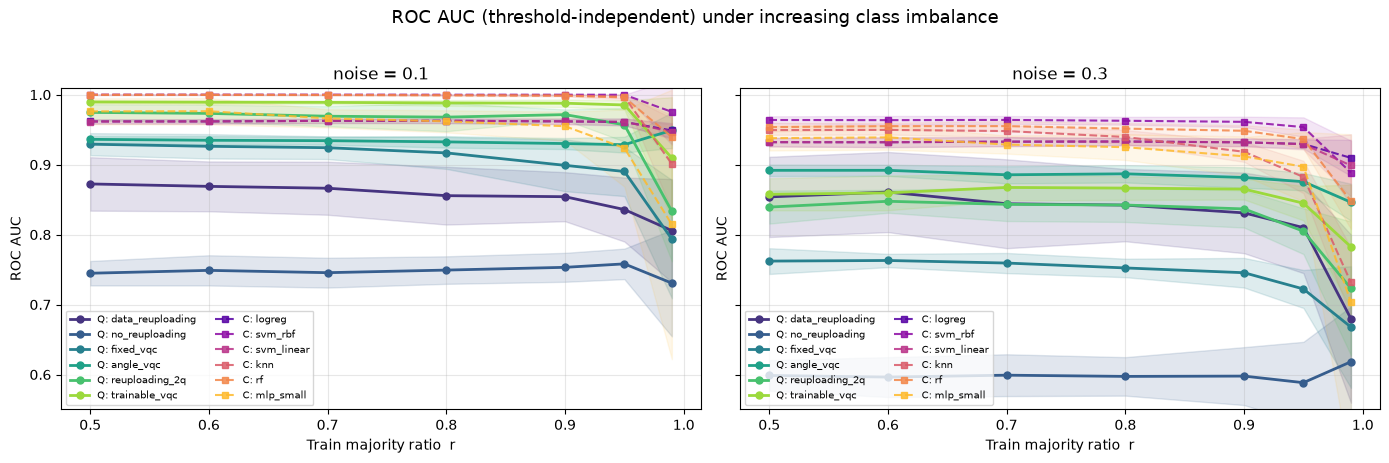

In [18]:
# AUC degradation curves: identical layout to §6 but the y-axis is the
# threshold-independent ROC AUC. Solid = quantum, dashed = classical, bands
# are +-1 std across the 12 seeds; the dotted line at 0.5 marks chance ranking.
def auc_degradation_plot(noise, ax):
    agg = qi.aggregate(results_by_noise[noise], by=('model', 'ratio'),
                       metric='roc_auc')
    cmap_q = plt.cm.viridis(np.linspace(0.15, 0.85, len(CONFIG['quantum_models'])))
    cmap_c = plt.cm.plasma(np.linspace(0.15, 0.85, len(CONFIG['classical_models'])))
    rs = sorted(CONFIG['ratios'])

    def collect(mname):
        means, stds = [], []
        for r in rs:
            row = next((x for x in agg
                        if x['model'] == mname and x['ratio'] == r), None)
            means.append(row['balanced_accuracy_mean'] if row else np.nan)
            stds.append(row['balanced_accuracy_std'] if row else 0.0)
        return np.array(rs), np.array(means), np.array(stds)

    for mname, color in zip(CONFIG['quantum_models'], cmap_q):
        x, mu, sd = collect(mname)
        ax.plot(x, mu, '-o', color=color, linewidth=2, markersize=5,
                label=f'Q: {mname}')
        ax.fill_between(x, mu - sd, mu + sd, color=color, alpha=0.15)
    for mname, color in zip(CONFIG['classical_models'], cmap_c):
        x, mu, sd = collect(mname)
        ax.plot(x, mu, '--s', color=color, linewidth=1.5, markersize=4,
                alpha=0.85, label=f'C: {mname}')
        ax.fill_between(x, mu - sd, mu + sd, color=color, alpha=0.10)
    ax.axhline(0.5, color='black', linestyle=':', linewidth=0.8, alpha=0.4)
    ax.set_xlabel('Train majority ratio  r')
    ax.set_ylabel('ROC AUC')
    ax.set_title(f'noise = {noise}')
    ax.set_ylim([0.55, 1.01])
    ax.grid(True, alpha=0.3)
    ax.legend(loc='lower left', fontsize=7, ncol=2)

fig, axes = plt.subplots(1, len(CONFIG['noise_levels']),
                         figsize=(7 * len(CONFIG['noise_levels']), 4.5),
                         sharey=True)
for ax, noise in zip(np.atleast_1d(axes), CONFIG['noise_levels']):
    auc_degradation_plot(noise, ax)
plt.suptitle('ROC AUC (threshold-independent) under increasing class imbalance',
             y=1.02, fontsize=13)
plt.tight_layout()
plt.savefig('figures/case2-auc-degradation.png', dpi=130, bbox_inches='tight')
plt.show()

In [19]:
# Same pre-registered protocol (Friedman omnibus + Holm-corrected pairwise
# Wilcoxon), now on the threshold-independent ROC AUC instead of BA.
auc_tables = {}
print('AUC Friedman omnibus + Holm-significant pair counts per (noise, ratio):')
print('=' * 70)
for noise in CONFIG['noise_levels']:
    auc_tables[noise] = qi.friedman_wilcoxon_holm(
        results_by_noise[noise], metric='roc_auc')
    print(f'\n  noise = {noise}')
    print(f'  {"r":<6}{"chi^2":>11}{"p_friedman":>13}{"#Holm-sig/66":>15}')
    for r in sorted(auc_tables[noise].keys()):
        st = auc_tables[noise][r]
        nsig = sum(1 for v in st['pairwise'].values() if v['reject_holm'])
        print(f'  {r:<6.2f}{st["friedman_stat"]:>11.2f}'
              f'{st["friedman_p"]:>13.3e}{nsig:>12d}/66')

def auc_q_beats_c(tables, qm, cm, r, sign, alpha=0.05):
    """sign=+1: count ratios where Q>C certified; sign=-1: where C>Q certified."""
    st = tables[r]
    if np.isnan(st['friedman_p']) or st['friedman_p'] >= alpha:
        return False
    pair = st['pairwise']
    if (qm, cm) in pair:
        info = pair[(qm, cm)]
        return info['reject_holm'] and ((info['mean_diff'] > 0) == (sign > 0))
    if (cm, qm) in pair:
        info = pair[(cm, qm)]
        return info['reject_holm'] and ((info['mean_diff'] < 0) == (sign > 0))
    return False

for sign, title in [(+1, 'Q > C'), (-1, 'C > Q')]:
    print('\n' + '=' * 70)
    print(f'AUC advantage matrix: #ratios (of 7) where Wilcoxon+Holm '
          f'certifies {title}')
    for noise in CONFIG['noise_levels']:
        print(f'\n  noise = {noise}')
        print(f'  {"Q model":<20}' + ''.join(c.rjust(13)
                                              for c in CONFIG['classical_models']))
        for qm in CONFIG['quantum_models']:
            line = f'  {qm:<20}'
            for cm in CONFIG['classical_models']:
                wins = sum(1 for r in CONFIG['ratios']
                           if auc_q_beats_c(auc_tables[noise], qm, cm, r, sign))
                line += f'{wins}/7'.rjust(13)
            print(line)

AUC Friedman omnibus + Holm-significant pair counts per (noise, ratio):



  noise = 0.1
  r           chi^2   p_friedman   #Holm-sig/66
  0.50       124.34    2.422e-21          55/66
  0.60       124.26    2.510e-21          56/66
  0.70       124.83    1.931e-21          57/66
  0.80       123.65    3.331e-21          58/66
  0.90       127.57    5.391e-22          57/66
  0.93       126.03    1.107e-21          60/66
  0.95       124.65    2.094e-21          57/66
  0.96       112.05    7.127e-19          43/66
  0.98       102.59    5.475e-17          35/66
  0.99        86.64    7.565e-14          27/66



  noise = 0.3
  r           chi^2   p_friedman   #Holm-sig/66
  0.50       123.58    3.452e-21          56/66
  0.60       123.78    3.139e-21          57/66
  0.70       124.88    1.881e-21          59/66
  0.80       122.27    6.333e-21          55/66
  0.90       122.04    7.049e-21          55/66
  0.93       121.62    8.576e-21          54/66
  0.95       119.37    2.425e-20          49/66
  0.96       115.40    1.523e-19          44/66
  0.98       113.89    3.055e-19          42/66
  0.99       101.06    1.099e-16          36/66

AUC advantage matrix: #ratios (of 7) where Wilcoxon+Holm certifies Q > C

  noise = 0.1
  Q model                    logreg      svm_rbf   svm_linear          knn           rf    mlp_small
  data_reuploading              0/7          0/7          0/7          0/7          0/7          0/7
  no_reuploading                0/7          0/7          0/7          0/7          0/7          0/7
  fixed_vqc                     0/7          0/7          0/7    

### Test-set ROC curves

AUC collapses the whole ranking quality into one scalar; the *shape* of the
ROC curve shows **where** on the operating range each model pays for the
imbalance: a curve that hugs the y-axis is good at cheap recall (low FPR),
one that only bulges near (1,1) is good only at expensive recall. Two models
with identical AUC can have very different shapes.

The cell below re-runs the grid slice for the two extreme ratios (balanced
$r=0.5$ and severe $r=0.99$) at both noise levels, capturing the per-sample
test scores that the cached `case2_grid.json` does not store (same
seeds, handler and hyperparameters, so the AUC values on the curves match
the tables above to float precision). That re-run costs ~30 min of CPU, so
the cell is **guarded**: if `figures/case2-roc-curves.png` already exists it
just displays it. Delete the figure (or set `FORCE_ROC = True`) to
regenerate.

[noise=0.1  ratio=0.5]


  data_reuploading     AUC=0.872


  no_reuploading       AUC=0.745


  fixed_vqc            AUC=0.929


  angle_vqc            AUC=0.936


...

  reuploading_2q       AUC=0.723


  trainable_vqc        AUC=0.782
  logreg               AUC=0.910
  svm_rbf              AUC=0.889
  svm_linear           AUC=0.899
  knn                  AUC=0.732


  rf                   AUC=0.848


  mlp_small            AUC=0.704


Saved figures/case2-roc-curves.png


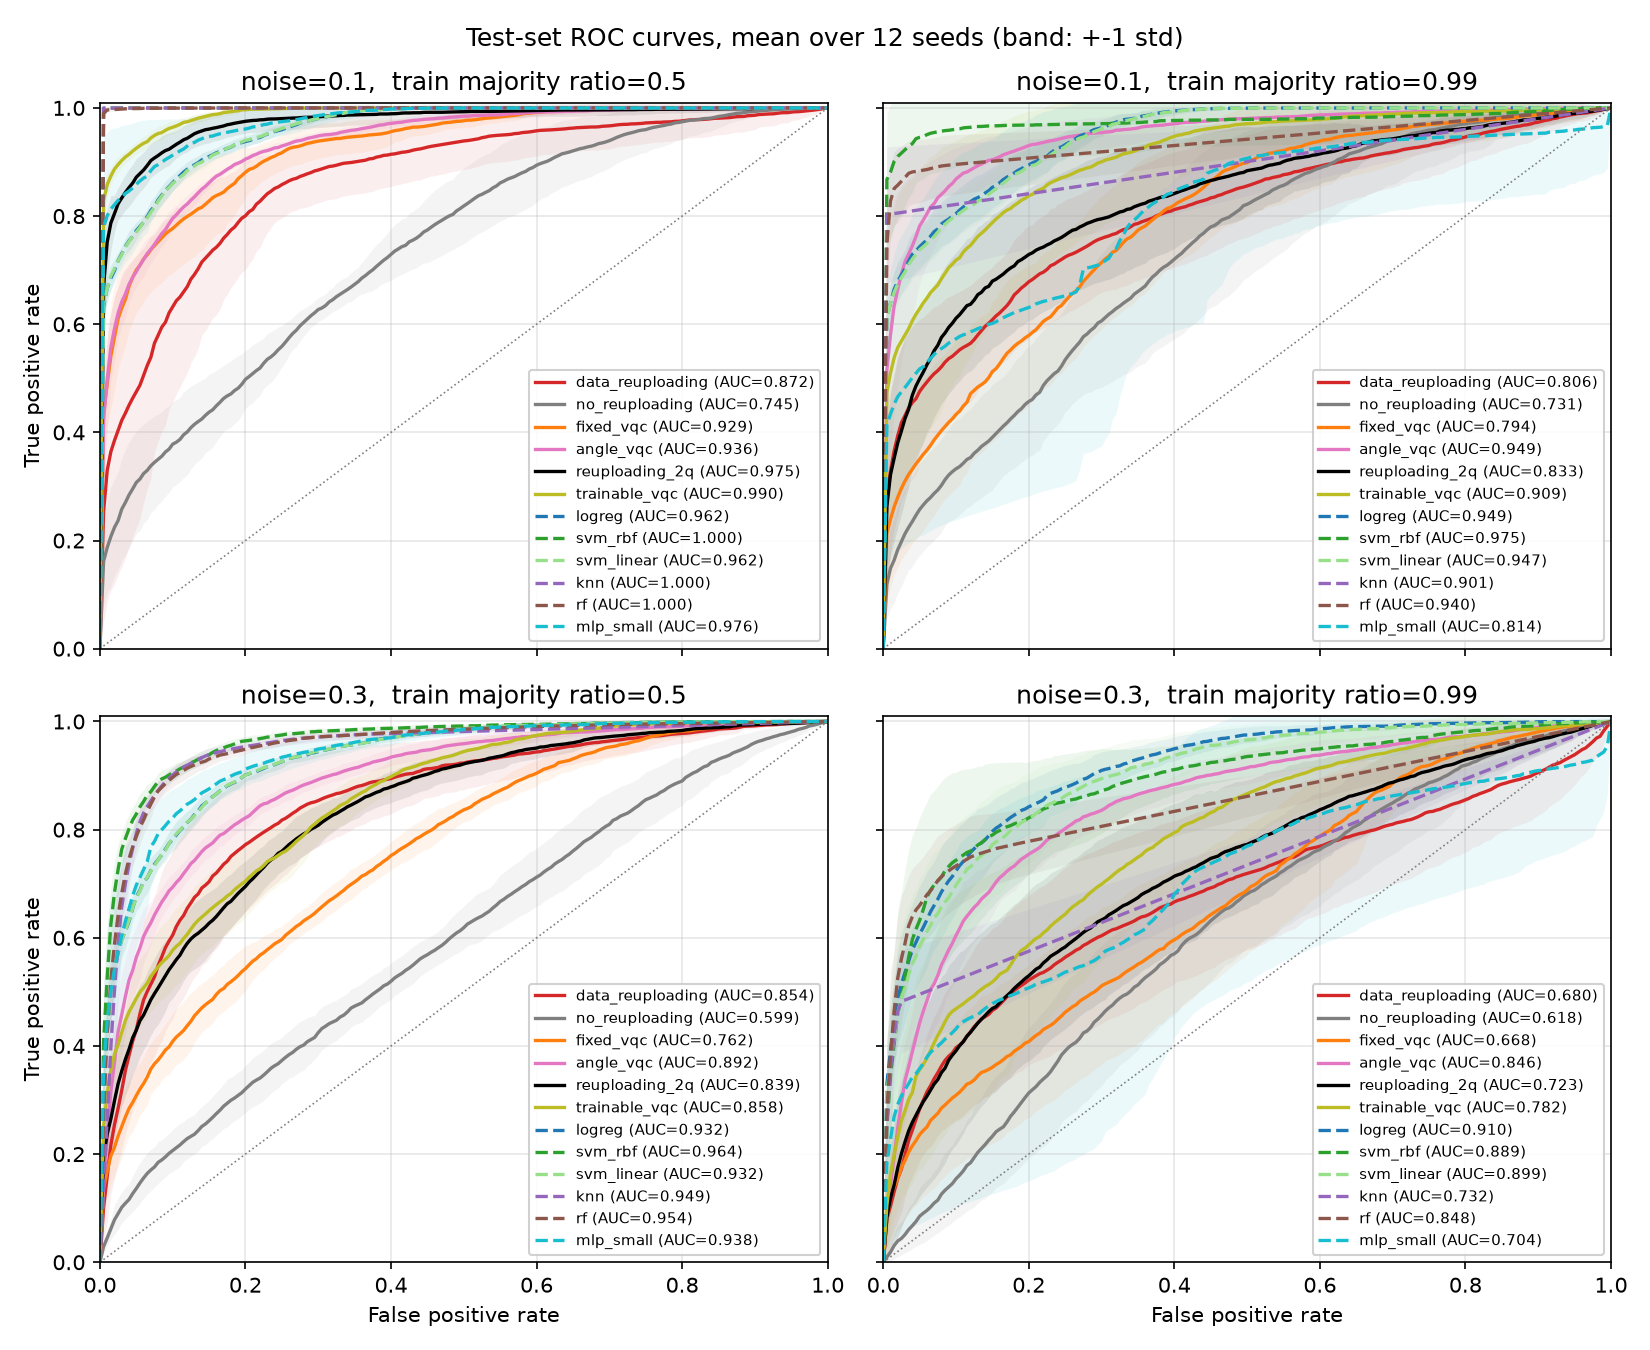

In [20]:
# --- Test-set ROC curves, mean over the 12 seeds (figure-guarded) -----------
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc as sk_auc

ROC_FIG = 'figures/case2-roc-curves.png'
FORCE_ROC = False

ROC_RATIOS = [0.5, 0.99]                    # the two extremes of the grid
FPR_GRID = np.linspace(0.0, 1.0, 201)       # common grid for seed-averaging

ROC_COLOURS = {
    'data_reuploading': '#d62728', 'no_reuploading': '#7f7f7f',
    'fixed_vqc':        '#ff7f0e', 'angle_vqc':      '#e377c2',
    'reuploading_2q':   '#000000', 'trainable_vqc':  '#bcbd22',
    'logreg':           '#1f77b4', 'svm_rbf':        '#2ca02c', 'svm_linear':     '#98df8a',
    'knn':              '#9467bd', 'rf':             '#8c564b',
    'mlp_small':        '#17becf',
}

if os.path.exists(ROC_FIG) and not FORCE_ROC:
    print(f'{ROC_FIG} present -> skipping the ~30 min score re-run. '
          f'(Delete the figure or set FORCE_ROC=True to regenerate.)')
else:
    def _roc_run_and_score(model_name, noise, ratio, seed):
        """Re-run one (model, noise, ratio, seed) experiment and return
        (y_test, scores_test): mirrors qi.run_one but exposes the continuous
        test scores instead of only the aggregated metrics."""
        Xb, yb = qi.make_balanced_dataset(n_total=8000, noise=noise, seed=42)
        X_tr, y_tr, X_va, y_va, X_te, y_te = qi.make_imbalanced_split(
            Xb, yb, train_ratio_majority=ratio,
            n_train=500, n_val=400, n_test=1200, seed=seed)
        X_tr_h, y_tr_h, sw_tr_h = qi.apply_class_weight(X_tr, y_tr)
        model = (qi.QuantumModel(model_name, n_iter=200, lr=0.015)
                 if model_name in qi.QuantumModel.SPEC
                 else qi.ClassicalModel(model_name))
        # Shared preprocessing: every model receives the same rescaled
        # inputs, matching qi.run_one.
        X_tr_use, X_va_use, X_te_use = qi.rescale_to_pi(X_tr_h, X_va, X_te)
        state = model.fit(X_tr_use, y_tr_h, sw_tr_h, X_va_use, y_va, seed=seed)
        return y_te, np.asarray(model.predict_score(state, X_te_use))

    def _mean_roc(curves):
        """Vertical averaging over seeds: interpolate TPR on a common FPR
        grid (the standard scikit-learn recipe)."""
        tprs, aucs = [], []
        for fpr, tpr in curves:
            t = np.interp(FPR_GRID, fpr, tpr)
            t[0] = 0.0
            tprs.append(t)
            aucs.append(sk_auc(fpr, tpr))
        tprs = np.vstack(tprs)
        return tprs.mean(axis=0), tprs.std(axis=0), float(np.mean(aucs))

    fig, axes = plt.subplots(len(CONFIG['noise_levels']), len(ROC_RATIOS),
                             figsize=(11, 9), sharex=True, sharey=True)
    for i, noise in enumerate(CONFIG['noise_levels']):
        for j, ratio in enumerate(ROC_RATIOS):
            ax = axes[i, j]
            print(f'[noise={noise}  ratio={ratio}]')
            for m in ALL_MODELS:
                curves = []
                for s in CONFIG['seeds']:
                    y_te, scores = _roc_run_and_score(m, noise, ratio, s)
                    fpr, tpr, _ = roc_curve(y_te, scores)
                    curves.append((fpr, tpr))
                tpr_m, tpr_s, auc_m = _mean_roc(curves)
                ls = '-' if m in CONFIG['quantum_models'] else '--'
                ax.plot(FPR_GRID, tpr_m, color=ROC_COLOURS[m], linestyle=ls,
                        linewidth=1.6, label=f'{m} (AUC={auc_m:.3f})')
                ax.fill_between(FPR_GRID, tpr_m - tpr_s, tpr_m + tpr_s,
                                color=ROC_COLOURS[m], alpha=0.08, linewidth=0)
                print(f'  {m:<20s} AUC={auc_m:.3f}')
            ax.plot([0, 1], [0, 1], color='gray', linewidth=0.8, linestyle=':')
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1.01)
            ax.set_title(f'noise={noise},  train majority ratio={ratio}')
            ax.grid(True, alpha=0.3)
            ax.legend(loc='lower right', fontsize=7, framealpha=0.9)
    for ax in axes[-1, :]:
        ax.set_xlabel('False positive rate')
    for ax in axes[:, 0]:
        ax.set_ylabel('True positive rate')
    fig.suptitle('Test-set ROC curves, mean over 12 seeds (band: +-1 std)',
                 fontsize=12)
    fig.tight_layout()
    fig.savefig(ROC_FIG, dpi=150)
    plt.close(fig)
    print(f'Saved {ROC_FIG}')

from IPython.display import Image, display
display(Image(ROC_FIG))

### Reading the AUC results

The threshold-independent picture **confirms** the balanced-accuracy
conclusion; it does not overturn it.

* **AUC is higher than BA almost everywhere**, which is expected: removing the
  thresholding step measures pure ranking quality. The lift is largest for the
  gradient-trained and linear models (trainable VQC at $\eta=0.1$, $r=0.5$:
  BA $0.931 \to$ AUC $0.990$; logreg at $\eta=0.3$: $0.848 \to 0.932$) and
  smallest for kNN, whose 5-neighbour vote produces a coarse 6-level score so
  its AUC *equals* its thresholded BA at $r=0.99$ ($0.911$ at $\eta=0.1$,
  $0.728$ at $\eta=0.3$). The key point is that this uniform lift **does not
  reorder quantum against the strong classical baselines**: `svm_rbf` sits at
  AUC $\approx 1.000$ for $r \le 0.95$ on $\eta=0.1$ ($0.978$ at $r=0.99$)
  and $0.968$ at $\eta=0.3$, above every quantum model at every ratio.
* **The advantage matrix keeps the same structure.** On $\eta=0.1$ the
  trainable VQC certifies 6/7 over each linear baseline and 6/7 over the
  capacity-matched MLP (vs 3/7 under BA); the Reuploading-2Q's BA wins largely dissolve under
  AUC (1/7 over each linear baseline, 1/7 over `mlp_small`, vs 5/7 and 2/7 under BA),
  which says its BA advantage is partly threshold-mediated; the Angle VQC's
  single $r=0.99$ BA win over the MLP does not survive on AUC. On $\eta=0.3$ no quantum model
  beats any classical baseline at any ratio.
* **One strong-baseline exception appears, and it is informative about kNN,
  not about the quantum models**: at $\eta=0.3$, $r=0.99$ the Angle VQC
  certifies a win over `knn` under AUC ($0.846$ vs $0.728$). kNN's coarse
  6-level score ranks barely better than its thresholded prediction, and at
  the extreme ratio it collapses; `svm_rbf` and `rf` remain unbeaten by every
  quantum model on both datasets. This is a post-hoc control, not part of
  the pre-registered conclusion.
* **The MLP's AUC collapse at $r=0.99$** ($0.687$ at $\eta=0.1$, $0.652$ at
  $\eta=0.3$, with $\sigma \approx 0.28$) explains why the trainable VQC's
  AUC wins over it are more consistent than its BA wins: the MLP's raw scores
  rank barely better than chance under extreme imbalance even though
  threshold tuning rescues its BA to $\sim 0.70$.
* **Robustness ranking**: the Angle VQC is the most AUC-robust model at
  $\eta=0.1$ ($\Delta = -0.013$; its AUC *rises* at the extreme ratio),
  `logreg` leads among the competitive models at $\eta=0.3$
  ($\Delta = 0.020$; the No-Reuploading control's negative slope reflects a
  uniformly weak model, not robustness worth having), and the MLP is the
  least robust on both ($\Delta \approx 0.28$).

**Bottom line.** Nothing significant in the quantum models' favour emerges
against the strong baselines from the threshold-independent metric. Had
threshold tuning been masking a latent quantum ranking advantage, AUC would
have surfaced it; instead the only AUC-specific certification against a
strong baseline (Angle VQC over kNN at the most extreme corner of the
high-noise dataset) reflects the coarseness of kNN's score, and the
pre-registered BA conclusion stands under both metrics.


## 15. Reading the results

* **§6 (degradation curves)** is the main. Look at the panel for each
  noise level. Flat = robust; collapsing toward 0.5 = the model has reverted
  to predicting the majority.
* **§7 (head-to-head bars at r = 0.99)** is where any quantum advantage is
  most likely to appear or fail to appear. The capacity-matched comparisons
  pit the quantum models against `mlp_small` (17 params, closest to the
  16-param Fixed, Angle and Reuploading-2Q VQCs, one step below the
  20-param trainable VQC); the kernel and tree methods are included as
  strong context baselines, not as direct capacity-matched comparators.
* **§8 (Friedman + Wilcoxon + Holm)** is the formal pre-registered protocol.
  Only Holm-adjusted $p < 0.05$ pairs count.
* **§9 (advantage table)** condenses §8 into one matrix per noise level.
* **§10 (robustness slope)** orthogonalises "good in absolute terms" from
  "robust to imbalance" — a model can be the second-best and still the most
  robust.
* **§11 (cost)** is the reality check. If a quantum model is 0.01 BA better
  but 1000× slower, the practical conclusion is unchanged.
* **§14 (ROC AUC)** is the threshold-independent control. Because BA is taken
  after threshold tuning, AUC checks whether the conclusion is an artefact of the
  threshold step. It is not: removing thresholding does not surface any hidden
  quantum ranking advantage, and the negative conclusion holds under both metrics.

The two-dataset structure is what gives this case study its main contribution.
A conclusion supported by both noise levels is much stronger than a
conclusion supported by only one: the main of the original work was
specific to a setting (noise=0.1) where kernel methods saturate. The added
noise=0.3 panel tests whether removing that structural advantage restores
the QML models' competitiveness, and the answer is reported above.